# Comparação de Paradigmas de Despacho sob Captação Imperfeita de Demanda

**Projeto de Pesquisa Operacional — notebook único, didático e reprodutível.**

Este notebook compara empiricamente três paradigmas de despacho de recursos sob
**captação imperfeita de demanda** (parte da demanda real nunca é observada no
momento da decisão):

1. **Predict-then-Optimize (PTO)** — previsão + otimização matemática;
2. **Reinforcement Learning (RL)** — política sequencial aprendida por reforço;
3. **MIP/Online** — programação inteira mista com reotimização em *rolling horizon*.

> **Pergunta científica.** Sob captação imperfeita, qual paradigma entrega maior
> **disponibilidade** (fração da demanda **real** atendida) e como cada um degrada
> quando a confiabilidade da captação cai?

O notebook é executável de cima para baixo em um ambiente limpo. As primeiras
células concentram configuração e utilitários; o corpo do notebook permanece enxuto.

## Seção 0 — Configuração, dependências e utilitários

Centralizamos aqui: imports, detecção de solver MIP (Gurobi → CBC), sementes,
parâmetros globais (`CONFIG`) e funções utilitárias reutilizadas pelas seções
seguintes. Nada de lógica de negócio ainda.

In [1]:
from __future__ import annotations

import os
import time
import math
import json
import warnings
import urllib.request
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Callable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

sns.set_theme(context="notebook", style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["figure.dpi"] = 110

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

print("Ambiente numérico carregado.")
print(f"  numpy  {np.__version__}")
print(f"  pandas {pd.__version__}")

Ambiente numérico carregado.
  numpy  2.0.2
  pandas 3.0.6


In [2]:
# ------------------------------------------------------------------
# Detecção de solver MIP: tenta Gurobi (licença acadêmica/comercial),
# cai para CBC via PuLP automaticamente. O restante do notebook usa
# a função resolve_mip(...) e não precisa saber qual backend está ativo.
# ------------------------------------------------------------------
SOLVER_BACKEND = None  # "gurobi" | "cbc"

try:
    import gurobipy as gp
    from gurobipy import GRB

    # Testa se há licença utilizável criando um modelo trivial.
    _env = gp.Env(empty=True)
    _env.setParam("OutputFlag", 0)
    _env.start()
    _m = gp.Model(env=_env)
    _m.dispose()
    _env.dispose()
    SOLVER_BACKEND = "gurobi"
except Exception as _e:  # pragma: no cover - depende do ambiente
    SOLVER_BACKEND = None

if SOLVER_BACKEND is None:
    import pulp  # fallback garantido
    SOLVER_BACKEND = "cbc"

print(f"Backend de otimização MIP selecionado: {SOLVER_BACKEND.upper()}")

Backend de otimização MIP selecionado: GUROBI


In [3]:
# ------------------------------------------------------------------
# Reprodutibilidade: semente global única propagada a numpy e torch.
# ------------------------------------------------------------------
GLOBAL_SEED = 42

def set_global_seed(seed: int = GLOBAL_SEED) -> None:
    import random as _random
    _random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.use_deterministic_algorithms(False)
    except Exception:
        pass

set_global_seed()
print(f"Semente global fixada em {GLOBAL_SEED}.")

Semente global fixada em 42.


In [4]:
# ------------------------------------------------------------------
# CONFIG: parâmetros globais do estudo. Um único ponto de verdade.
# ------------------------------------------------------------------
@dataclass
class Config:
    # --- Dados ---
    data_url: str = ("https://d37ci6vzurychx.cloudfront.net/trip-data/"
                     "yellow_tripdata_2024-01.parquet")
    data_dir: Path = Path("data")
    data_file: str = "yellow_tripdata_2024-01.parquet"

    # --- Escopo espaço-temporal ---
    n_zones: int = 10            # top-N zonas por volume
    step_minutes: int = 15       # granularidade da decisão
    steps_per_day: int = field(init=False)

    # --- Split temporal (por blocos de dias) ---
    train_days: int = 14
    val_days: int = 7
    test_days: int = 7

    # --- Recursos / capacidade (calibrados a partir dos dados) ---
    fleet_K: int = field(default=0)      # preenchido na calibração
    service_c: int = field(default=0)    # preenchido na calibração
    oracle_target: float = 0.88          # disponibilidade-alvo do oráculo

    # --- Penalidades do objetivo (default: foco em disponibilidade pura) ---
    lambda_idle: float = 0.0
    lambda_repos: float = 0.0

    # --- MIP/Online ---
    horizon_H: int = 4           # janelas à frente no rolling horizon
    mip_timeout_s: float = 5.0   # timeout por reotimização

    # --- RL ---
    rl_episodes: int = 300
    rl_gamma: float = 0.95
    rl_lr: float = 1e-3

    def __post_init__(self):
        self.steps_per_day = (24 * 60) // self.step_minutes
        self.data_dir = Path(self.data_dir)

CONFIG = Config()
CONFIG.data_dir.mkdir(parents=True, exist_ok=True)
print("CONFIG inicializado:")
for k, v in asdict(CONFIG).items():
    print(f"  {k:16s} = {v}")

CONFIG inicializado:
  data_url         = https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet
  data_dir         = data
  data_file        = yellow_tripdata_2024-01.parquet
  n_zones          = 10
  step_minutes     = 15
  steps_per_day    = 96
  train_days       = 14
  val_days         = 7
  test_days        = 7
  fleet_K          = 0
  service_c        = 0
  oracle_target    = 0.88
  lambda_idle      = 0.0
  lambda_repos     = 0.0
  horizon_H        = 4
  mip_timeout_s    = 5.0
  rl_episodes      = 300
  rl_gamma         = 0.95
  rl_lr            = 0.001


In [5]:
# ------------------------------------------------------------------
# Utilitários de métrica e avaliação (reutilizados por todos os paradigmas).
# ------------------------------------------------------------------
def availability(D: np.ndarray, A: np.ndarray, c: int) -> float:
    '''Disponibilidade = sum(min(D, c*A)) / sum(D).

    D : demanda REAL (ground truth), shape (T, Z)
    A : veículos alocados, shape (T, Z)
    c : capacidade de serviço por veículo
    '''
    served = np.minimum(D, c * A).sum()
    total = D.sum()
    return float(served / total) if total > 0 else 1.0


def served_units(D: np.ndarray, A: np.ndarray, c: int) -> np.ndarray:
    return np.minimum(D, c * A)


def idle_capacity(D: np.ndarray, A: np.ndarray, c: int) -> float:
    '''Capacidade ociosa total: c*A - demanda atendida (>= 0).'''
    return float(np.clip(c * A - D, 0, None).sum())


def objective_value(D, A, c, lam_idle=0.0, lam_repos=0.0):
    '''Objetivo comum (maximização) usado na AVALIAÇÃO a posteriori.'''
    served = served_units(D, A, c).sum()
    idle = np.clip(c * A - D, 0, None).sum()
    repos = np.abs(np.diff(A, axis=0)).sum() if A.shape[0] > 1 else 0.0
    return float(served - lam_idle * idle - lam_repos * repos)


print("Utilitários de métrica definidos: availability, served_units, "
      "idle_capacity, objective_value.")

Utilitários de métrica definidos: availability, served_units, idle_capacity, objective_value.


## Seção 1 — Definição formal do problema

### 1.1 Entidades, recursos e horizonte

- **Zonas** $z \in Z$, $|Z| = N$ (top-$N$ *taxi zones* de Manhattan por volume).
- **Recurso**: frota de $K$ veículos homogêneos, realocáveis a cada passo.
- **Capacidade de serviço** $c$: cada veículo atende até $c$ unidades de demanda por passo.
- **Horizonte**: dia dividido em $T$ passos de $\Delta t$ (padrão 15 min, $T = 96$).
- **Decisão**: no início de cada passo $t$, escolher $a_{z,t} \in \mathbb{Z}_{\ge 0}$
  (veículos na zona $z$), com $\sum_z a_{z,t} \le K$.

### 1.2 Processos (separação explícita — anti-vazamento)

| Símbolo | Significado | Disponível na decisão? |
|---------|-------------|------------------------|
| $D_{z,t}$ | **demanda real** (ground truth) | ❌ só na avaliação |
| $O_{z,t}$ | **demanda observada** (captada) | ✅ até $t-1$ |
| $\mathcal{I}_t$ | informação disponível em $t$ | ✅ (histórico de $O$ + calendário) |

A captação imperfeita filtra a demanda real:
$$ O_{z,t} = \sum_{i=1}^{D_{z,t}} \mathbb{1}[u_i < p^{capt}_{z,t}], \quad u_i \sim \mathcal{U}(0,1). $$

### 1.3 Métrica principal — disponibilidade

$$ \text{Disponibilidade} = \frac{\sum_{z,t} \min(D_{z,t},\, c\,a_{z,t})}{\sum_{z,t} D_{z,t}} \in [0,1]. $$

É a fração da **demanda real** atendida. **Crucial**: o numerador usa $D$ (avaliação
*a posteriori*), mas a decisão $a_{z,t}$ só pode depender de $\mathcal{I}_t$.

### 1.4 Função objetivo comum

$$
\max_{a} \; \underbrace{\sum_{z,t} \min(D_{z,t}, c\,a_{z,t})}_{\text{demanda atendida}}
\; - \; \lambda_{\text{ocioso}} \sum_{z,t} (c\,a_{z,t} - D_{z,t})^+
\; - \; \lambda_{\text{repos}} \sum_{t,z} |a_{z,t} - a_{z,t-1}|
$$

sujeito a $\sum_z a_{z,t} \le K$ e $a_{z,t} \in \mathbb{Z}_{\ge 0}$.
Default $\lambda = 0$ (disponibilidade pura); penalidades entram na análise de sensibilidade.

### 1.5 Papel de cada paradigma

- **PTO**: estima $\hat D_{z,t}$ de $\mathcal{I}_t$, depois resolve o MIP de alocação com $\hat D$.
- **RL**: aprende $\pi(a_t \mid \mathcal{I}_t)$ maximizando recompensa alinhada à disponibilidade.
- **MIP/Online**: resolve MIP em janela $[t, t+H]$ com previsão simples, reotimizando a cada passo.

## Seção 2 — Carga de dados, EDA e simulação da captação imperfeita

Pipeline:
1. **Download/cache** do Parquet do NYC TLC (domínio público).
2. **Agregação** em tensor de demanda real $D \in \mathbb{Z}^{\,\text{dias} \times T \times Z}$.
3. **EDA** rápida (perfil intradiário e por zona).
4. **Gerador de captação imperfeita** configurável (alta/média/baixa; MAR/MNAR).

In [6]:
def download_tlc_data(cfg: Config) -> Path:
    '''Baixa (com cache) o arquivo Parquet do NYC TLC.'''
    dest = cfg.data_dir / cfg.data_file
    if dest.exists() and dest.stat().st_size > 0:
        print(f"[cache] usando {dest} ({dest.stat().st_size/1e6:.1f} MB)")
        return dest
    print(f"[download] {cfg.data_url}")
    tmp = dest.with_suffix(".tmp")
    urllib.request.urlretrieve(cfg.data_url, tmp)
    tmp.rename(dest)
    print(f"[ok] salvo em {dest} ({dest.stat().st_size/1e6:.1f} MB)")
    return dest


raw_path = download_tlc_data(CONFIG)

[cache] usando data\yellow_tripdata_2024-01.parquet (50.0 MB)


In [7]:
def load_and_aggregate(path: Path, cfg: Config) -> tuple[np.ndarray, list[int], pd.DatetimeIndex]:
    '''Lê o Parquet e agrega em tensor de demanda real D[dia, passo, zona].

    Retorna:
      D      : np.ndarray int, shape (n_days, steps_per_day, n_zones)
      zones  : lista de LocationIDs selecionados (top-N por volume)
      days   : DatetimeIndex com as datas (eixo 0 de D)
    '''
    cols = ["tpep_pickup_datetime", "PULocationID"]
    df = pd.read_parquet(path, columns=cols)
    df = df.rename(columns={"tpep_pickup_datetime": "ts", "PULocationID": "zone"})

    # Mantém apenas o mês de referência (remove timestamps espúrios do TLC).
    ref = df["ts"].dt.to_period("M").mode().iloc[0]
    df = df[df["ts"].dt.to_period("M") == ref].copy()

    # Top-N zonas por volume total.
    top = df["zone"].value_counts().head(cfg.n_zones).index.tolist()
    top = sorted(top)
    df = df[df["zone"].isin(top)].copy()
    zone_to_idx = {z: i for i, z in enumerate(top)}

    # Índices temporais: dia e passo intradiário.
    df["date"] = df["ts"].dt.normalize()
    minutes = df["ts"].dt.hour * 60 + df["ts"].dt.minute
    df["step"] = (minutes // cfg.step_minutes).astype(int)
    df["zidx"] = df["zone"].map(zone_to_idx).astype(int)

    days = pd.DatetimeIndex(sorted(df["date"].unique()))
    day_to_idx = {d: i for i, d in enumerate(days)}
    df["didx"] = df["date"].map(day_to_idx).astype(int)

    D = np.zeros((len(days), cfg.steps_per_day, cfg.n_zones), dtype=np.int32)
    np.add.at(D, (df["didx"].values, df["step"].values, df["zidx"].values), 1)

    print(f"Tensor de demanda real D: shape {D.shape} "
          f"(dias={D.shape[0]}, passos/dia={D.shape[1]}, zonas={D.shape[2]})")
    print(f"Total de corridas agregadas: {D.sum():,}")
    return D, top, days


D_real, ZONES, DAYS = load_and_aggregate(raw_path, CONFIG)

Tensor de demanda real D: shape (31, 96, 10) (dias=31, passos/dia=96, zonas=10)
Total de corridas agregadas: 1,167,527


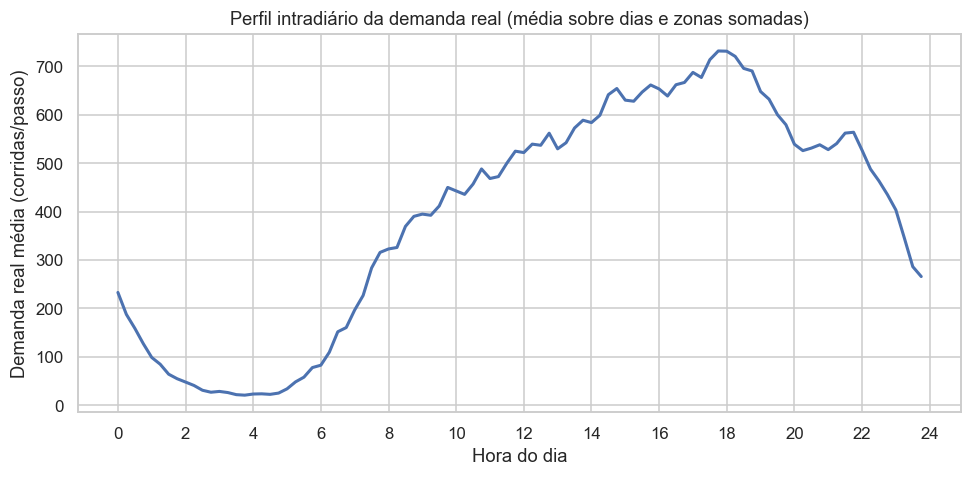

In [8]:
# --- EDA 1: perfil intradiário médio (soma nas zonas, média nos dias) ---
intraday = D_real.sum(axis=2).mean(axis=0)  # shape (steps_per_day,)
hours = np.arange(CONFIG.steps_per_day) * CONFIG.step_minutes / 60.0

fig, ax = plt.subplots()
ax.plot(hours, intraday, lw=2)
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Demanda real média (corridas/passo)")
ax.set_title("Perfil intradiário da demanda real (média sobre dias e zonas somadas)")
ax.set_xticks(range(0, 25, 2))
plt.tight_layout(); plt.show()

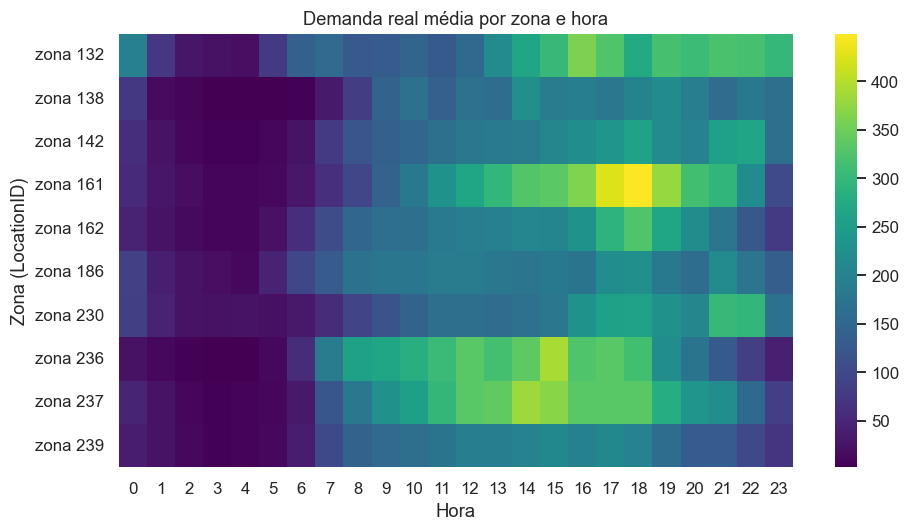

In [9]:
# --- EDA 2: heatmap zona x hora (demanda média) ---
by_zone_hour = D_real.mean(axis=0)  # (steps, zones)
# agrega passos em horas para leitura
steps_per_hour = 60 // CONFIG.step_minutes
hourly = by_zone_hour.reshape(24, steps_per_hour, CONFIG.n_zones).sum(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(hourly.T, cmap="viridis", ax=ax,
            xticklabels=range(24),
            yticklabels=[f"zona {z}" for z in ZONES])
ax.set_xlabel("Hora"); ax.set_ylabel("Zona (LocationID)")
ax.set_title("Demanda real média por zona e hora")
plt.tight_layout(); plt.show()

### 2.1 Gerador de captação imperfeita

Modelamos a probabilidade de captação por passo/zona com uma sigmoide sobre
covariáveis, permitindo mecanismos **MAR** (depende de hora/zona observáveis) e
**MNAR** (depende da própria carga real — picos subcaptados):

$$
p^{capt}_{z,t} = \sigma\!\big(\beta_0 + \beta_{\text{hora}}(t) + \beta_{\text{zona}}(z)
+ \gamma \cdot \tilde D_{z,t}\big),
$$

onde $\tilde D$ é a carga real normalizada e $\gamma \neq 0$ ativa o componente MNAR.
O intercepto $\beta_0$ é **calibrado** para atingir a captação média alvo do cenário.

In [10]:
@dataclass
class CaptureScenario:
    name: str
    target_mean: float   # captação média desejada
    beta_hour_amp: float # amplitude da dependência horária (MAR)
    beta_zone_amp: float # amplitude da dependência por zona (MAR)
    gamma_mnar: float    # peso do componente MNAR (<=0 subcapta picos)
    noise_sd: float      # ruído logit


SCENARIOS = {
    "alta":  CaptureScenario("alta",  0.90, 0.25, 0.20,  0.00, 0.05),
    "media": CaptureScenario("media", 0.65, 0.60, 0.50, -0.40, 0.15),
    "baixa": CaptureScenario("baixa", 0.40, 0.90, 0.70, -1.20, 0.30),
}


def _sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def build_capture_prob(D: np.ndarray, sc: CaptureScenario, cfg: Config,
                       seed: int = GLOBAL_SEED) -> np.ndarray:
    '''Constrói p_capt[dia, passo, zona] para um cenário, calibrando beta0
    para que a média (ponderada pela demanda) fique ~ target_mean.'''
    rng = np.random.default_rng(seed)
    n_days, T, Z = D.shape

    # Componente horário (padrão senoidal) e por zona (fixo por zona).
    hour_frac = (np.arange(T) / T) * 2 * np.pi
    beta_hour = sc.beta_hour_amp * np.sin(hour_frac - np.pi / 3)      # (T,)
    beta_zone = sc.beta_zone_amp * rng.standard_normal(Z)            # (Z,)

    # Carga real normalizada por (passo,zona) -> componente MNAR.
    Dz = D.astype(float)
    denom = Dz.max() if Dz.max() > 0 else 1.0
    load_norm = Dz / denom

    noise = sc.noise_sd * rng.standard_normal(D.shape)

    logit_base = (beta_hour[None, :, None]
                  + beta_zone[None, None, :]
                  + sc.gamma_mnar * load_norm
                  + noise)

    # Calibra beta0 por busca binária para atingir a captação média alvo
    # (ponderada pela demanda, que é o que de fato importa operacionalmente).
    w = Dz / Dz.sum()
    lo, hi = -10.0, 10.0
    for _ in range(60):
        b0 = 0.5 * (lo + hi)
        p = _sigmoid(b0 + logit_base)
        mean_w = float((p * w).sum())
        if mean_w < sc.target_mean:
            lo = b0
        else:
            hi = b0
    p_capt = _sigmoid(b0 + logit_base)
    return np.clip(p_capt, 1e-4, 1 - 1e-4)


def apply_capture(D: np.ndarray, p_capt: np.ndarray, seed: int = GLOBAL_SEED) -> np.ndarray:
    '''Gera demanda observada O ~ Binomial(D, p_capt). Vetorizado.'''
    rng = np.random.default_rng(seed + 777)
    return rng.binomial(D, p_capt).astype(np.int32)


# Pré-computa p_capt e O para cada cenário (semente fixa -> reprodutível).
P_CAPT, D_OBS = {}, {}
for key, sc in SCENARIOS.items():
    P_CAPT[key] = build_capture_prob(D_real, sc, CONFIG)
    D_OBS[key] = apply_capture(D_real, P_CAPT[key])
    eff = D_OBS[key].sum() / D_real.sum()
    print(f"Cenário {key:5s}: captação média (alvo {sc.target_mean:.2f}) "
          f"-> efetiva {eff:.3f}")

Cenário alta : captação média (alvo 0.90) -> efetiva 0.900
Cenário media: captação média (alvo 0.65) -> efetiva 0.650
Cenário baixa: captação média (alvo 0.40) -> efetiva 0.400


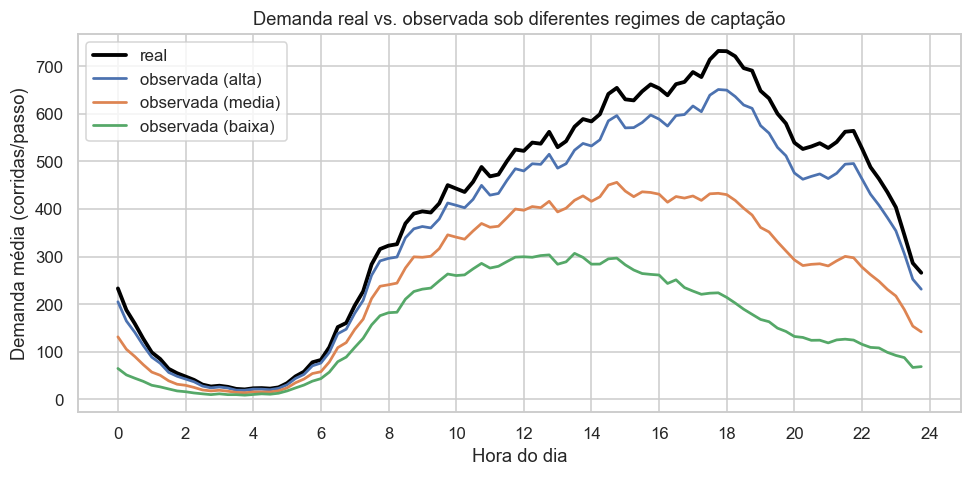

In [11]:
# --- Visualiza o efeito da captação no perfil intradiário ---
fig, ax = plt.subplots()
ax.plot(hours, D_real.sum(axis=2).mean(axis=0), lw=2.5, color="black", label="real")
for key in ["alta", "media", "baixa"]:
    ax.plot(hours, D_OBS[key].sum(axis=2).mean(axis=0), lw=1.8, label=f"observada ({key})")
ax.set_xlabel("Hora do dia"); ax.set_ylabel("Demanda média (corridas/passo)")
ax.set_title("Demanda real vs. observada sob diferentes regimes de captação")
ax.legend(); ax.set_xticks(range(0, 25, 2))
plt.tight_layout(); plt.show()

## Seção 3 — Ambiente de simulação comum e baselines

Todos os paradigmas atuam sobre o **mesmo** ambiente, garantindo comparação justa.
O ambiente expõe a um controlador apenas a informação legítima em cada passo
($\mathcal{I}_t$) e avalia a decisão contra a demanda **real**.

### 3.1 Contrato do ambiente

- `reset(day)` → estado inicial do dia.
- `observe()` → $\mathcal{I}_t$ (histórico de observadas + calendário). **Nunca** $D_{\ge t}$.
- `step(a_t)` → aplica alocação, revela $D_{\cdot,t}$ **apenas para registro/avaliação**,
  avança o relógio e devolve recompensa = demanda atendida no passo.

### 3.2 Split temporal

Blocos contíguos de dias (sem embaralhar): treino → validação → teste.

In [12]:
def make_temporal_split(n_days: int, cfg: Config) -> dict[str, np.ndarray]:
    '''Divide os dias em blocos contíguos treino/val/teste (sem shuffle).'''
    idx = np.arange(n_days)
    tr = idx[: cfg.train_days]
    va = idx[cfg.train_days: cfg.train_days + cfg.val_days]
    te = idx[cfg.train_days + cfg.val_days:
             cfg.train_days + cfg.val_days + cfg.test_days]
    split = {"train": tr, "val": va, "test": te}
    for k, v in split.items():
        print(f"  {k:5s}: {len(v)} dias -> índices {v[:3]}{'...' if len(v) > 3 else ''}")
    return split


SPLIT = make_temporal_split(D_real.shape[0], CONFIG)

  train: 14 dias -> índices [0 1 2]...
  val  : 7 dias -> índices [14 15 16]...
  test : 7 dias -> índices [21 22 23]...


In [13]:
class DispatchEnv:
    '''Ambiente de despacho para um único dia.

    Expõe apenas informação legítima no instante da decisão. A demanda real é
    usada somente para computar recompensa/avaliação APÓS a ação (sem vazamento).

    Parâmetros
    ----------
    D_real_day : (T, Z) demanda real do dia (ground truth).
    D_obs_day  : (T, Z) demanda observada do dia (captação imperfeita).
    cfg        : Config.
    '''

    def __init__(self, D_real_day: np.ndarray, D_obs_day: np.ndarray, cfg: Config):
        self.Dr = D_real_day
        self.Do = D_obs_day
        self.cfg = cfg
        self.T, self.Z = D_real_day.shape
        self.reset()

    def reset(self):
        self.t = 0
        self.alloc_hist = np.zeros((self.T, self.Z), dtype=np.int32)
        self.prev_alloc = np.zeros(self.Z, dtype=np.int32)
        return self.observe()

    def observe(self) -> dict:
        '''Informação disponível no instante t (I_t): histórico de OBSERVADAS
        até t-1, índice do passo e alocação anterior. Nunca demanda real futura.'''
        obs_hist = self.Do[: self.t]  # observadas de 0..t-1
        return {
            "t": self.t,
            "T": self.T,
            "step_of_day": self.t,
            "obs_history": obs_hist,
            "last_obs": self.Do[self.t - 1] if self.t > 0 else np.zeros(self.Z, int),
            "prev_alloc": self.prev_alloc.copy(),
        }

    def step(self, a_t: np.ndarray):
        '''Aplica alocação a_t no passo atual. Retorna (obs, reward, done, info).

        reward = demanda REAL atendida no passo (alinhada à disponibilidade).
        '''
        a_t = np.asarray(a_t, dtype=np.int32)
        assert a_t.shape == (self.Z,), f"ação deve ter shape ({self.Z},)"
        assert a_t.sum() <= self.cfg.fleet_K + 1e-9, "viola capacidade da frota K"

        d_now = self.Dr[self.t]  # revelado SÓ agora, para avaliação
        served = np.minimum(d_now, self.cfg.service_c * a_t)
        reward = float(served.sum())

        # penalidades opcionais
        idle = np.clip(self.cfg.service_c * a_t - d_now, 0, None).sum()
        repos = np.abs(a_t - self.prev_alloc).sum()
        reward -= self.cfg.lambda_idle * idle + self.cfg.lambda_repos * repos

        self.alloc_hist[self.t] = a_t
        self.prev_alloc = a_t
        self.t += 1
        done = self.t >= self.T
        info = {"served": float(served.sum()), "demand": float(d_now.sum()),
                "idle": float(idle), "repos": float(repos)}
        return (self.observe() if not done else None), reward, done, info


print("Classe DispatchEnv definida (ambiente comum a todos os paradigmas).")

Classe DispatchEnv definida (ambiente comum a todos os paradigmas).


In [14]:
def run_policy_on_days(policy: Callable[[dict, Config], np.ndarray],
                       D_real_sel: np.ndarray, D_obs_sel: np.ndarray,
                       cfg: Config) -> dict:
    '''Executa uma política sobre um conjunto de dias e agrega métricas.

    policy(obs, cfg) -> vetor de alocação a_t (shape (Z,)), com sum <= K.
    Retorna dict com tensores de alocação e métricas operacionais/computacionais.
    '''
    n_days = D_real_sel.shape[0]
    A_all = np.zeros_like(D_real_sel)
    t0 = time.perf_counter()
    decide_times = []

    for d in range(n_days):
        env = DispatchEnv(D_real_sel[d], D_obs_sel[d], cfg)
        obs = env.reset()
        done = False
        while not done:
            td = time.perf_counter()
            a_t = policy(obs, cfg)
            decide_times.append(time.perf_counter() - td)
            obs, _, done, _ = env.step(a_t)
        A_all[d] = env.alloc_hist

    wall = time.perf_counter() - t0
    avail = availability(D_real_sel, A_all, cfg.service_c)
    return {
        "alloc": A_all,
        "availability": avail,
        "idle": idle_capacity(D_real_sel, A_all, cfg.service_c),
        "objective": objective_value(D_real_sel, A_all, cfg.service_c,
                                     cfg.lambda_idle, cfg.lambda_repos),
        "wall_time_s": wall,
        "mean_decision_ms": float(np.mean(decide_times) * 1000),
    }


print("Runner run_policy_on_days definido.")

Runner run_policy_on_days definido.


### 3.3 Calibração da frota

Escolhemos $K$ e $c$ de modo que o **oráculo** (informação perfeita de $D$) atinja a
disponibilidade-alvo (`oracle_target`), deixando folga para os paradigmas se
diferenciarem. Fixamos $c$ e buscamos o menor $K$ que atinge o alvo com a política
oráculo (alocação proporcional ótima à demanda real, respeitando $K$).

In [15]:
def waterfill_alloc(demand_units: np.ndarray, K: int, c: int) -> np.ndarray:
    '''Aloca K veículos para maximizar demanda atendida dado 'demand_units'
    por zona (guloso ótimo: cada veículo vai onde o ganho marginal é maior).

    Como a cobertura por veículo é c e o ganho é min(demanda_restante, c),
    o guloso por maior demanda residual é ótimo para este subproblema separável.
    '''
    Z = len(demand_units)
    a = np.zeros(Z, dtype=np.int32)
    residual = demand_units.astype(float).copy()
    for _ in range(int(K)):
        z = int(np.argmax(residual))
        if residual[z] <= 0:
            break  # sem ganho marginal -> parar (evita ociosidade)
        a[z] += 1
        residual[z] -= c
    return a


print("Função de alocação gulosa ótima (waterfill) definida. "
      "O oráculo é avaliado diretamente sobre o tensor real em evaluate_oracle.")

Função de alocação gulosa ótima (waterfill) definida. O oráculo é avaliado diretamente sobre o tensor real em evaluate_oracle.


In [16]:
# O oráculo precisa ver a demanda real do passo. Em vez de burlar o env,
# executamos o oráculo diretamente sobre o tensor real (limite superior teórico).
def evaluate_oracle(D_real_sel: np.ndarray, cfg: Config) -> dict:
    n_days, T, Z = D_real_sel.shape
    A = np.zeros_like(D_real_sel)
    for d in range(n_days):
        for t in range(T):
            A[d, t] = waterfill_alloc(D_real_sel[d, t], cfg.fleet_K, cfg.service_c)
    return {"alloc": A, "availability": availability(D_real_sel, A, cfg.service_c)}


def calibrate_fleet(D_real_sel: np.ndarray, cfg: Config,
                    c_candidates=(2, 3, 4, 5)) -> tuple[int, int, float]:
    '''Busca (K, c) tal que o oráculo ~ oracle_target. Para cada c, acha o
    menor K (busca binária) que atinge o alvo; escolhe o par mais 'apertado'.'''
    peak = D_real_sel.sum(axis=2).max()  # pico de demanda total num passo
    best = None
    for c in c_candidates:
        lo, hi = 1, int(math.ceil(peak / c)) + 5
        while lo < hi:
            mid = (lo + hi) // 2
            cfg.fleet_K, cfg.service_c = mid, c
            av = evaluate_oracle(D_real_sel, cfg)["availability"]
            if av >= cfg.oracle_target:
                hi = mid
            else:
                lo = mid + 1
        cfg.fleet_K, cfg.service_c = lo, c
        av = evaluate_oracle(D_real_sel, cfg)["availability"]
        cand = (lo, c, av)
        if best is None or lo < best[0]:
            best = cand
    return best


# Calibra usando os dias de treino (evita olhar o teste).
_K, _c, _av = calibrate_fleet(D_real[SPLIT["train"]], CONFIG)
CONFIG.fleet_K, CONFIG.service_c = _K, _c
print(f"Frota calibrada: K={_K} veículos, c={_c} unidades/veículo "
      f"-> oráculo (treino) = {_av:.3f} disponibilidade")

oracle_test = evaluate_oracle(D_real[SPLIT['test']], CONFIG)
print(f"Oráculo no TESTE: disponibilidade = {oracle_test['availability']:.3f} "
      f"(teto superior de referência)")

Frota calibrada: K=101 veículos, c=5 unidades/veículo -> oráculo (treino) = 0.881 disponibilidade
Oráculo no TESTE: disponibilidade = 0.852 (teto superior de referência)


In [17]:
# --- Baseline ingênua: aloca proporcional à ÚLTIMA demanda OBSERVADA ---
def naive_policy(obs: dict, cfg: Config) -> np.ndarray:
    '''Política ingênua: usa a última demanda observada como proxy e faz
    waterfill. Representa 'reagir ao que se enxerga', sem correção de captação.'''
    last = obs["last_obs"].astype(float)
    if last.sum() <= 0:
        # sem histórico: distribui uniformemente
        a = np.zeros(cfg.n_zones, dtype=np.int32)
        a[: cfg.fleet_K] = 1 if cfg.fleet_K <= cfg.n_zones else 0
        base, rem = divmod(cfg.fleet_K, cfg.n_zones)
        a = np.full(cfg.n_zones, base, dtype=np.int32)
        a[:rem] += 1
        return a
    return waterfill_alloc(last, cfg.fleet_K, cfg.service_c)


# Avalia baseline ingênua no teste, para cada cenário de captação.
print("Baseline ingênua (teste), por cenário de captação:")
baseline_naive = {}
for key in ["alta", "media", "baixa"]:
    res = run_policy_on_days(naive_policy,
                             D_real[SPLIT["test"]], D_OBS[key][SPLIT["test"]],
                             CONFIG)
    baseline_naive[key] = res
    print(f"  {key:5s}: disponibilidade={res['availability']:.3f} "
          f"| decisão={res['mean_decision_ms']:.3f} ms")

Baseline ingênua (teste), por cenário de captação:
  alta : disponibilidade=0.785 | decisão=0.092 ms


  media: disponibilidade=0.673 | decisão=0.079 ms
  baixa: disponibilidade=0.440 | decisão=0.052 ms


## Seção 4 — Paradigma 1: Predict-then-Optimize (PTO)

A ideia do PTO é desacoplar **previsão** e **decisão**: primeiro estimamos os
parâmetros operacionais (demanda), depois resolvemos um programa matemático que
toma a decisão ótima **dado** o parâmetro estimado.

### 4.1 O desafio específico: prever a demanda REAL a partir da OBSERVADA

O ponto crítico sob captação imperfeita é que treinar um preditor para reproduzir
a demanda **observada** propaga o viés de subcaptação para a otimização. Então o
alvo de treino é a demanda **real** $D$ (disponível no histórico de treino, *ex post*),
e as *features* usam apenas informação legítima no instante da decisão:

- calendário (hora do dia via *sin/cos*, dia da semana);
- identidade da zona (one-hot);
- *lags* da demanda **observada** ($O_{z,t-1}, O_{z,t-2}, \dots$) e médias móveis;
- estimativa de confiabilidade de captação $\hat p^{capt}_{z,t}$ (ver 4.2).

> Isso é, em essência, uma correção de *reporting bias*: aprendemos o mapeamento
> $\mathcal{I}_t \mapsto \mathbb{E}[D_{z,t}]$ diretamente, em vez de modelar só $O$.

### 4.2 Estimação da confiabilidade de captação

No histórico de treino conhecemos $D$ e $O$, logo podemos estimar
$\hat p^{capt}_{z,h} = \frac{\sum O}{\sum D}$ por (zona, hora). Essa tabela é
informação legítima (vem do passado) e serve tanto de *feature* quanto de fator
de *de-biasing* $\hat D^{\text{deb}}_{z,t} = O_{z,t} / \hat p^{capt}_{z,h(t)}$.

### 4.3 Otimização acoplada

Com a previsão $\hat D$, a alocação ótima do passo é separável e resolvida pelo
MIP de alocação (equivalente ao *waterfill* quando $\lambda=0$; usamos o MIP
explícito para permitir penalidades e manter a arquitetura PTO fiel).

In [18]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

def build_capture_reliability(D_real_sel, D_obs_sel, cfg):
    '''Estima p_capt[zona, hora] = sum(O)/sum(D) no conjunto de TREINO.

    Retorna matriz (n_zones, 24) usada como feature e para de-biasing.
    '''
    steps_per_hour = 60 // cfg.step_minutes
    n_days, T, Z = D_real_sel.shape
    hour_of_step = (np.arange(T) // steps_per_hour)  # 0..23
    rel = np.ones((Z, 24))
    for h in range(24):
        mask = hour_of_step == h
        dr = D_real_sel[:, mask, :].sum(axis=(0, 1))  # (Z,)
        do = D_obs_sel[:, mask, :].sum(axis=(0, 1))
        rel[:, h] = np.where(dr > 0, do / np.maximum(dr, 1), 1.0)
    return np.clip(rel, 0.05, 1.0)


print("Estimador de confiabilidade de captação definido.")

Estimador de confiabilidade de captação definido.


In [19]:
def make_features(D_obs_sel, cfg, reliability, n_lags=3):
    '''Monta matriz de features X e metadados (dia, passo, zona) para cada
    ponto (dia, t>=n_lags, zona). Usa SÓ informação legítima: lags da OBSERVADA,
    calendário e a confiabilidade estimada. O alvo y é preenchido fora (real).

    Retorna (X, idx) onde idx = array (N,3) com (dia_local, passo, zona).
    '''
    n_days, T, Z = D_obs_sel.shape
    steps_per_hour = 60 // cfg.step_minutes
    rows, idx = [], []
    for d in range(n_days):
        for t in range(n_lags, T):
            hour = t // steps_per_hour
            ang = 2 * np.pi * t / T
            sin_t, cos_t = math.sin(ang), math.cos(ang)
            for z in range(Z):
                lags = [D_obs_sel[d, t - k, z] for k in range(1, n_lags + 1)]
                ma = np.mean(lags)
                zone_oh = [1.0 if zz == z else 0.0 for zz in range(Z)]
                feat = [sin_t, cos_t, hour / 23.0, ma, reliability[z, hour]] + lags + zone_oh
                rows.append(feat)
                idx.append((d, t, z))
    return np.asarray(rows, float), np.asarray(idx, int)


def fit_pto_predictor(cfg, scenario_key):
    '''Treina o preditor de demanda REAL para um cenário de captação.

    Alvo: D_real (ex post, só no treino). Features: informação legítima.
    Retorna (modelo, reliability, n_lags) e imprime MAE de validação.
    '''
    set_global_seed()
    n_lags = 3
    tr, va = SPLIT["train"], SPLIT["val"]
    rel = build_capture_reliability(D_real[tr], D_OBS[scenario_key][tr], cfg)

    Xtr, itr = make_features(D_OBS[scenario_key][tr], cfg, rel, n_lags)
    ytr = np.array([D_real[tr][d, t, z] for d, t, z in itr], float)
    Xva, iva = make_features(D_OBS[scenario_key][va], cfg, rel, n_lags)
    yva = np.array([D_real[va][d, t, z] for d, t, z in iva], float)

    model = GradientBoostingRegressor(n_estimators=200, max_depth=3,
                                      learning_rate=0.05, subsample=0.8,
                                      random_state=GLOBAL_SEED)
    model.fit(Xtr, ytr)
    mae = mean_absolute_error(yva, np.clip(model.predict(Xva), 0, None))
    print(f"  [PTO:{scenario_key}] MAE val (demanda real) = {mae:.3f} "
          f"| baseline de-bias MAE = "
          f"{mean_absolute_error(yva, _debias_pred(Xva, cfg, n_lags)):.3f}")
    return model, rel, n_lags


def _debias_pred(X, cfg, n_lags):
    '''Previsão de referência por de-biasing puro: lag1_observado / p_capt.
    As colunas de X seguem a ordem de make_features: [sin,cos,hora,ma,rel,
    lag1,...,lagL, onehot...]. Logo rel=col 4 e lag1=col 5.'''
    rel_col = X[:, 4]
    lag1 = X[:, 5]
    return lag1 / np.maximum(rel_col, 0.05)


print("Pipeline preditivo PTO definido (features, de-biasing e treino).")

Pipeline preditivo PTO definido (features, de-biasing e treino).


In [20]:
def solve_allocation_mip(demand_hat, K, c, prev_alloc=None,
                         lam_idle=0.0, lam_repos=0.0, timeout=5.0):
    '''Resolve o MIP de alocação de UM passo dado a demanda estimada por zona.

        max  sum_z served_z - lam_idle*idle_z - lam_repos*|a_z - prev_z|
        s.a. served_z <= demand_hat_z ; served_z <= c*a_z
             sum_z a_z <= K ; a_z inteiro >= 0

    Backend: Gurobi se disponível, senão CBC (PuLP). Retorna vetor a (Z,).
    '''
    Z = len(demand_hat)
    prev = np.zeros(Z) if prev_alloc is None else np.asarray(prev_alloc, float)

    if SOLVER_BACKEND == "gurobi":
        m = gp.Model("alloc"); m.Params.OutputFlag = 0
        m.Params.TimeLimit = timeout
        a = m.addVars(Z, vtype=GRB.INTEGER, lb=0, name="a")
        s = m.addVars(Z, lb=0, name="served")
        dev = m.addVars(Z, lb=0, name="dev")  # |a - prev|
        m.addConstr(gp.quicksum(a[z] for z in range(Z)) <= K)
        for z in range(Z):
            m.addConstr(s[z] <= demand_hat[z])
            m.addConstr(s[z] <= c * a[z])
            idle_z = c * a[z] - s[z]
            m.addConstr(dev[z] >= a[z] - prev[z])
            m.addConstr(dev[z] >= prev[z] - a[z])
            _ = idle_z
        obj = gp.quicksum(
            s[z] - lam_idle * (c * a[z] - s[z]) - lam_repos * dev[z]
            for z in range(Z))
        m.setObjective(obj, GRB.MAXIMIZE)
        m.optimize()
        if m.SolCount == 0:
            return waterfill_alloc(np.asarray(demand_hat), K, c)  # fallback viável
        return np.array([int(round(a[z].X)) for z in range(Z)], dtype=np.int32)

    # ---- fallback CBC via PuLP ----
    prob = pulp.LpProblem("alloc", pulp.LpMaximize)
    a = [pulp.LpVariable(f"a_{z}", lowBound=0, cat="Integer") for z in range(Z)]
    s = [pulp.LpVariable(f"s_{z}", lowBound=0) for z in range(Z)]
    dev = [pulp.LpVariable(f"d_{z}", lowBound=0) for z in range(Z)]
    prob += pulp.lpSum(s[z] - lam_idle * (c * a[z] - s[z]) - lam_repos * dev[z]
                       for z in range(Z))
    prob += pulp.lpSum(a) <= K
    for z in range(Z):
        prob += s[z] <= demand_hat[z]
        prob += s[z] <= c * a[z]
        prob += dev[z] >= a[z] - prev[z]
        prob += dev[z] >= prev[z] - a[z]
    prob.solve(pulp.PULP_CBC_CMD(msg=0, timeLimit=timeout))
    if pulp.LpStatus[prob.status] not in ("Optimal", "Not Solved"):
        return waterfill_alloc(np.asarray(demand_hat), K, c)
    return np.array([int(round(a[z].value() or 0)) for z in range(Z)], dtype=np.int32)


print("MIP de alocação de um passo definido (Gurobi/CBC).")

MIP de alocação de um passo definido (Gurobi/CBC).


In [21]:
def make_pto_policy(model, reliability, n_lags, cfg):
    '''Cria a política PTO: a cada passo monta features do estado, prevê a
    demanda real e resolve o MIP de alocação. Para t < n_lags (sem lags
    suficientes) cai no de-biasing simples sobre a última observada.
    '''
    steps_per_hour = 60 // cfg.step_minutes
    Z = cfg.n_zones

    def _policy(obs, cfg):
        t, T = obs["t"], obs["T"]
        hist = obs["obs_history"]  # (t, Z) observadas de 0..t-1
        hour = t // steps_per_hour
        if t < n_lags:
            # pouca história: de-biasing da última observada (ou uniforme)
            last = obs["last_obs"].astype(float)
            dhat = last / np.clip(reliability[:, hour], 0.05, 1.0)
            if dhat.sum() <= 0:
                base, rem = divmod(cfg.fleet_K, Z)
                a = np.full(Z, base, dtype=np.int32); a[:rem] += 1
                return a
            return solve_allocation_mip(dhat, cfg.fleet_K, cfg.service_c,
                                        obs["prev_alloc"], cfg.lambda_idle,
                                        cfg.lambda_repos, cfg.mip_timeout_s)
        ang = 2 * np.pi * t / T
        sin_t, cos_t = math.sin(ang), math.cos(ang)
        feats = []
        for z in range(Z):
            lags = [hist[t - k, z] for k in range(1, n_lags + 1)]
            ma = float(np.mean(lags))
            zone_oh = [1.0 if zz == z else 0.0 for zz in range(Z)]
            feats.append([sin_t, cos_t, hour / 23.0, ma, reliability[z, hour]]
                         + lags + zone_oh)
        dhat = np.clip(model.predict(np.asarray(feats, float)), 0, None)
        return solve_allocation_mip(dhat, cfg.fleet_K, cfg.service_c,
                                    obs["prev_alloc"], cfg.lambda_idle,
                                    cfg.lambda_repos, cfg.mip_timeout_s)
    return _policy


# Treina um preditor por cenário e avalia a política PTO no TESTE.
print("Treinando preditores PTO e avaliando no teste:")
pto_models, pto_results = {}, {}
for key in ["alta", "media", "baixa"]:
    mdl, rel, nl = fit_pto_predictor(CONFIG, key)
    pto_models[key] = (mdl, rel, nl)
    policy = make_pto_policy(mdl, rel, nl, CONFIG)
    res = run_policy_on_days(policy, D_real[SPLIT["test"]],
                             D_OBS[key][SPLIT["test"]], CONFIG)
    pto_results[key] = res
    print(f"  [PTO:{key}] disponibilidade={res['availability']:.3f} "
          f"| decisão={res['mean_decision_ms']:.2f} ms")

Treinando preditores PTO e avaliando no teste:


  [PTO:alta] MAE val (demanda real) = 7.746 | baseline de-bias MAE = 8.746
Restricted license - for non-production use only - expires 2026-11-23


  [PTO:alta] disponibilidade=0.794 | decisão=2.82 ms


  [PTO:media] MAE val (demanda real) = 8.033 | baseline de-bias MAE = 9.441


  [PTO:media] disponibilidade=0.792 | decisão=2.84 ms


  [PTO:baixa] MAE val (demanda real) = 9.237 | baseline de-bias MAE = 12.419


  [PTO:baixa] disponibilidade=0.782 | decisão=2.81 ms


## Seção 5 — Paradigma 2: Reinforcement Learning (Actor-Critic)

Aqui a decisão não passa por uma previsão explícita: o agente aprende uma política
$\pi_\theta(a_t \mid s_t)$ que mapeia o estado diretamente em alocação, maximizando
o retorno descontado da recompensa. Isso permite que o agente aprenda, de forma
implícita, a **compensar o viés de captação** apenas a partir do sinal de recompensa.

### 5.1 Formulação como MDP

- **Estado** $s_t$ (apenas informação legítima em $t$):
  calendário ($\sin, \cos$ do passo, hora normalizada), *lags* normalizados da
  demanda **observada**, confiabilidade de captação estimada $\hat p^{capt}_{z,h}$
  e a alocação anterior normalizada.
- **Ação** $a_t$: alocação inteira de $K$ veículos nas $Z$ zonas. Para tornar o
  espaço tratável, o ator emite **logits** por zona → *softmax* → proporções
  $w_z$; a alocação inteira é obtida por *largest-remainder* (apportionment) com
  $\sum_z a_z = K$. A exploração vem de amostrar $w$ de uma **Dirichlet**
  concentrada nos logits durante o treino.
- **Recompensa** $r_t = \sum_z \min(D_{z,t}, c\,a_{z,t})$ — exatamente a demanda
  **real** atendida no passo, normalizada por um fator de escala. Alinhada à
  disponibilidade.
- **Transição**: determinística no relógio; a aleatoriedade está na demanda.

### 5.2 Algoritmo

**Advantage Actor-Critic (A2C)** implementado do zero em PyTorch:
ator (política) + crítico (estimador de valor $V_\psi(s)$), vantagem
$A_t = G_t - V_\psi(s_t)$, com retornos descontados $G_t$, entropia para
exploração e *gradient clipping*. Sementes fixas garantem reprodutibilidade.

In [22]:
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device("cpu")  # ambiente é CPU-only; mantém determinismo


def largest_remainder_alloc(weights: np.ndarray, K: int) -> np.ndarray:
    '''Converte proporções (somam 1) em alocação inteira com soma exata K
    pelo método do maior resto (apportionment de Hamilton). Determinístico.'''
    raw = weights * K
    base = np.floor(raw).astype(int)
    rem = K - base.sum()
    if rem > 0:
        order = np.argsort(-(raw - base))  # maiores restos primeiro
        base[order[:rem]] += 1
    return base.astype(np.int32)


print(f"PyTorch {torch.__version__} | device={DEVICE}")
print("Apportionment largest-remainder definido.")

PyTorch 2.13.0+cpu | device=cpu
Apportionment largest-remainder definido.


In [23]:
class RLState:
    '''Constrói o vetor de estado s_t a partir da observação do ambiente,
    usando só informação legítima. Mantém a mesma ordenação de features no
    treino e na execução (crucial para coerência).'''

    def __init__(self, cfg, reliability, n_lags=3, demand_scale=None):
        self.cfg = cfg
        self.rel = reliability            # (Z, 24)
        self.n_lags = n_lags
        self.Z = cfg.n_zones
        self.steps_per_hour = 60 // cfg.step_minutes
        # escala de normalização dos lags/recompensa (robustez numérica)
        self.demand_scale = demand_scale or 1.0

    @property
    def dim(self):
        # [sin, cos, hora] + lags*Z + rel_hora*Z + prev_alloc*Z
        return 3 + self.n_lags * self.Z + self.Z + self.Z

    def build(self, obs) -> np.ndarray:
        t, T = obs["t"], obs["T"]
        hour = t // self.steps_per_hour
        ang = 2 * np.pi * t / T
        hist = obs["obs_history"]
        feats = [math.sin(ang), math.cos(ang), hour / 23.0]
        for k in range(1, self.n_lags + 1):
            if t - k >= 0:
                feats.extend((hist[t - k] / self.demand_scale).tolist())
            else:
                feats.extend([0.0] * self.Z)
        feats.extend(self.rel[:, hour].tolist())
        feats.extend((obs["prev_alloc"] / max(self.cfg.fleet_K, 1)).tolist())
        return np.asarray(feats, dtype=np.float32)


class ActorCritic(nn.Module):
    '''Rede compartilhada com duas cabeças: ator (logits por zona) e crítico
    (valor escalar do estado).'''

    def __init__(self, state_dim, n_zones, hidden=128):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
        )
        self.actor_head = nn.Linear(hidden, n_zones)
        self.critic_head = nn.Linear(hidden, 1)

    def forward(self, x):
        h = self.body(x)
        logits = self.actor_head(h)
        value = self.critic_head(h).squeeze(-1)
        return logits, value


print("RLState e ActorCritic definidos.")

RLState e ActorCritic definidos.


In [24]:
def train_rl_agent(cfg, scenario_key, verbose=True):
    '''Treina um agente A2C para um cenário de captação.

    - Episódio = um dia de TREINO (amostrado aleatoriamente).
    - Política: logits -> Dirichlet(alpha=softmax(logits)*conc) p/ exploração;
      proporções -> largest_remainder -> alocação inteira (soma = K).
    - Vantagem = retorno descontado - valor do crítico.
    - Early-stop por disponibilidade de VALIDAÇÃO.
    Retorna (modelo, state_builder, hist_val).
    '''
    set_global_seed()
    tr, va = SPLIT["train"], SPLIT["val"]
    rel = build_capture_reliability(D_real[tr], D_OBS[scenario_key][tr], cfg)
    scale = max(1.0, float(D_OBS[scenario_key][tr].mean()))
    sb = RLState(cfg, rel, n_lags=3, demand_scale=scale)

    torch.manual_seed(GLOBAL_SEED)
    net = ActorCritic(sb.dim, cfg.n_zones).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=cfg.rl_lr)
    reward_scale = float(D_real[tr].sum(axis=2).mean()) or 1.0
    concentration = 8.0  # concentração da Dirichlet (↑ = menos exploração)
    rng = np.random.default_rng(GLOBAL_SEED)

    best_val, best_state, hist_val = -1.0, None, []

    def rollout_day(day_real, day_obs, train=True):
        env = DispatchEnv(day_real, day_obs, cfg)
        obs = env.reset()
        logps, values, entropies, rewards = [], [], [], []
        done = False
        while not done:
            s = torch.from_numpy(sb.build(obs)).to(DEVICE)
            logits, value = net(s)
            probs = F.softmax(logits, dim=-1)
            if train:
                alpha = probs.detach().cpu().numpy() * concentration + 1e-3
                w = rng.dirichlet(alpha)
                # Projeta no interior do simplex: evita componentes 0/1 que
                # caem fora do suporte da Dirichlet e geram log_prob = +/-inf.
                w = np.clip(w, 1e-6, None)
                w = w / w.sum()
                dist = torch.distributions.Dirichlet(probs * concentration + 1e-3)
                w_t = torch.from_numpy(w.astype(np.float32))
                logp = dist.log_prob(w_t)
                ent = dist.entropy()
            else:
                w = probs.detach().cpu().numpy()
                logp = torch.tensor(0.0); ent = torch.tensor(0.0)
            a = largest_remainder_alloc(w, cfg.fleet_K)
            obs, reward, done, info = env.step(a)
            logps.append(logp); values.append(value)
            entropies.append(ent); rewards.append(reward / reward_scale)
        return logps, values, entropies, rewards, env

    for ep in range(cfg.rl_episodes):
        d = int(rng.integers(len(tr)))
        logps, values, entropies, rewards, _ = rollout_day(
            D_real[tr][d], D_OBS[scenario_key][tr][d], train=True)

        # retornos descontados
        G, returns = 0.0, []
        for r in reversed(rewards):
            G = r + cfg.rl_gamma * G
            returns.append(G)
        returns = torch.tensor(list(reversed(returns)), dtype=torch.float32)
        values_t = torch.stack(values)
        logps_t = torch.stack(logps)
        ent_t = torch.stack(entropies)

        adv = returns - values_t.detach()
        actor_loss = -(logps_t * adv).mean()
        critic_loss = F.mse_loss(values_t, returns)
        loss = actor_loss + 0.5 * critic_loss - 0.01 * ent_t.mean()

        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        opt.step()

        # validação periódica (greedy)
        if (ep + 1) % 25 == 0 or ep == cfg.rl_episodes - 1:
            net.eval()
            A = np.zeros_like(D_real[va])
            with torch.no_grad():
                for dv in range(len(va)):
                    *_unused, env = rollout_day(
                        D_real[va][dv], D_OBS[scenario_key][va][dv], train=False)
                    A[dv] = env.alloc_hist
            av = availability(D_real[va], A, cfg.service_c)
            hist_val.append((ep + 1, av))
            if av > best_val:
                best_val = av
                best_state = {k: v.clone() for k, v in net.state_dict().items()}
            net.train()
            if verbose:
                print(f"    ep {ep+1:3d} | val disponibilidade = {av:.3f} "
                      f"(melhor {best_val:.3f})")

    if best_state is not None:
        net.load_state_dict(best_state)
    net.eval()
    return net, sb, hist_val


print("Loop de treino A2C definido (train_rl_agent).")

Loop de treino A2C definido (train_rl_agent).


In [25]:
def make_rl_policy(net, state_builder, cfg):
    '''Política RL de execução (greedy): usa as proporções da softmax do ator
    diretamente, sem exploração, e converte em alocação inteira (soma = K).'''
    def _policy(obs, cfg):
        s = torch.from_numpy(state_builder.build(obs)).to(DEVICE)
        with torch.no_grad():
            logits, _ = net(s)
            w = F.softmax(logits, dim=-1).cpu().numpy()
        return largest_remainder_alloc(w, cfg.fleet_K)
    return _policy


# Treina um agente por cenário e avalia no TESTE. Sementes fixas -> reprodutível.
print("Treinando agentes RL (A2C) por cenário e avaliando no teste:")
rl_agents, rl_results, rl_curves = {}, {}, {}
for key in ["alta", "media", "baixa"]:
    print(f"  Cenário {key}:")
    net, sb, curve = train_rl_agent(CONFIG, key, verbose=True)
    rl_agents[key] = (net, sb)
    rl_curves[key] = curve
    policy = make_rl_policy(net, sb, CONFIG)
    res = run_policy_on_days(policy, D_real[SPLIT["test"]],
                             D_OBS[key][SPLIT["test"]], CONFIG)
    rl_results[key] = res
    print(f"  [RL:{key}] disponibilidade={res['availability']:.3f} "
          f"| decisão={res['mean_decision_ms']:.2f} ms")

Treinando agentes RL (A2C) por cenário e avaliando no teste:
  Cenário alta:


    ep  25 | val disponibilidade = 0.498 (melhor 0.498)


    ep  50 | val disponibilidade = 0.131 (melhor 0.498)


    ep  75 | val disponibilidade = 0.526 (melhor 0.526)


    ep 100 | val disponibilidade = 0.410 (melhor 0.526)


...

    ep 200 | val disponibilidade = 0.224 (melhor 0.713)


    ep 225 | val disponibilidade = 0.587 (melhor 0.713)


    ep 250 | val disponibilidade = 0.509 (melhor 0.713)


    ep 275 | val disponibilidade = 0.612 (melhor 0.713)


    ep 300 | val disponibilidade = 0.729 (melhor 0.729)
  [RL:baixa] disponibilidade=0.726 | decisão=0.11 ms


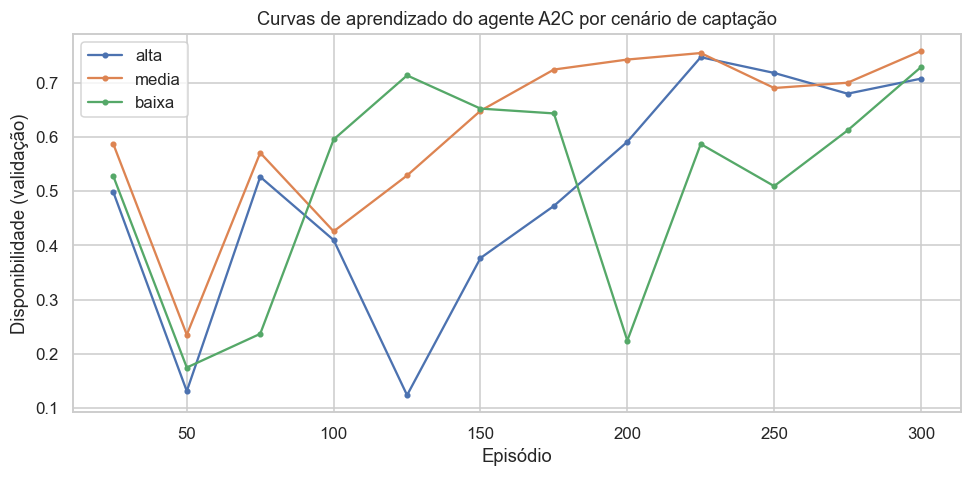

In [26]:
# Curvas de aprendizado (disponibilidade de validação ao longo dos episódios).
fig, ax = plt.subplots()
for key in ["alta", "media", "baixa"]:
    if rl_curves[key]:
        eps, avs = zip(*rl_curves[key])
        ax.plot(eps, avs, marker="o", ms=3, label=f"{key}")
ax.set_xlabel("Episódio"); ax.set_ylabel("Disponibilidade (validação)")
ax.set_title("Curvas de aprendizado do agente A2C por cenário de captação")
ax.legend(); plt.tight_layout(); plt.show()

## Seção 6 — Paradigma 3: MIP/Online com reotimização

Diferente do PTO (que resolve um subproblema **de um passo** com uma previsão
sofisticada), o paradigma MIP/Online explora a **estrutura temporal** da decisão:
a cada passo resolve um MIP **multi-período** sobre a janela $[t, t+H]$, aplica
apenas a decisão do passo corrente e **reotimiza** no passo seguinte com a
informação atualizada (*rolling / receding horizon*).

### 6.1 Previsão leve e online

Para isolar o efeito da **reotimização** (e não o da sofisticação preditiva, já
coberta pelo PTO), a previsão da demanda futura na janela usa um estimador leve e
*online*: média móvel da demanda **observada** recente, corrigida pela
confiabilidade de captação $\hat p^{capt}_{z,h}$ e por um fator sazonal horário.

### 6.2 MIP multi-período

$$
\max \sum_{\tau=t}^{t+H}\sum_z \Big[\min(\hat D_{z,\tau}, c\,a_{z,\tau})\Big]
- \lambda_{\text{repos}} \sum_{\tau} \sum_z |a_{z,\tau} - a_{z,\tau-1}|
$$

sujeito a $\sum_z a_{z,\tau} \le K$ para todo $\tau$, acoplamento de reposicionamento
entre passos consecutivos e integralidade. Apenas $a_{\cdot,t}$ é aplicado.

### 6.3 Robustez operacional

- **Timeout** por reotimização (`mip_timeout_s`): se o solver não prova otimalidade,
  usamos a melhor solução incumbente; se não há solução, caímos em um *fallback*
  viável (*waterfill* do passo corrente).
- **Viabilidade garantida**: as restrições sempre admitem $a=0$; logo o modelo
  nunca é inviável. Monitoramos *status*, *gap* e número de *timeouts*.

In [27]:
def forecast_window(obs, reliability, cfg, H):
    '''Previsão leve e online da demanda REAL para a janela [t, t+H].

    Usa a média da demanda observada recente (de-enviesada por reliability) como
    nível e a replica na janela. Mantém-se simples de propósito: o foco do
    paradigma é a reotimização, não a sofisticação preditiva (coberta pelo PTO).

    Retorna matriz Dhat (H+1, Z).
    '''
    t = obs["t"]
    Z = cfg.n_zones
    steps_per_hour = 60 // cfg.step_minutes
    hist = obs["obs_history"]  # (t, Z)

    # nível: média das últimas W observadas, de-enviesada pela confiabilidade
    W = 4
    if t > 0:
        recent = hist[max(0, t - W):t].astype(float)
        hour_now = t // steps_per_hour
        level = recent.mean(axis=0) / np.clip(reliability[:, hour_now], 0.05, 1.0)
    else:
        level = np.zeros(Z)

    # Replica o nível de-enviesado ao longo da janela (perfil plano, online).
    Dhat = np.tile(np.clip(level, 0, None), (H + 1, 1))
    return Dhat


print("Previsão online de janela definida (forecast_window).")

Previsão online de janela definida (forecast_window).


In [28]:
def solve_rolling_mip(Dhat, K, c, prev_alloc, cfg):
    '''Resolve o MIP multi-período sobre a janela e devolve (a_first, meta).

    Dhat : (H+1, Z) demanda estimada na janela.
    Aplica timeout; em timeout usa incumbente; sem solução -> fallback waterfill.
    meta: dict com status, gap, tempo, flag de timeout.
    '''
    Hp1, Z = Dhat.shape
    prev = np.asarray(prev_alloc, float)
    lam = cfg.lambda_repos
    t0 = time.perf_counter()

    if SOLVER_BACKEND == "gurobi":
        m = gp.Model("rolling"); m.Params.OutputFlag = 0
        m.Params.TimeLimit = cfg.mip_timeout_s
        a = m.addVars(Hp1, Z, vtype=GRB.INTEGER, lb=0, name="a")
        s = m.addVars(Hp1, Z, lb=0, name="s")
        dev = m.addVars(Hp1, Z, lb=0, name="dev")
        for k in range(Hp1):
            m.addConstr(gp.quicksum(a[k, z] for z in range(Z)) <= K)
            for z in range(Z):
                m.addConstr(s[k, z] <= Dhat[k, z])
                m.addConstr(s[k, z] <= c * a[k, z])
                prev_kz = prev[z] if k == 0 else a[k - 1, z]
                m.addConstr(dev[k, z] >= a[k, z] - prev_kz)
                m.addConstr(dev[k, z] >= prev_kz - a[k, z])
        obj = gp.quicksum(s[k, z] - lam * dev[k, z]
                          for k in range(Hp1) for z in range(Z))
        m.setObjective(obj, GRB.MAXIMIZE)
        m.optimize()
        wall = time.perf_counter() - t0
        timed_out = (m.Status == GRB.TIME_LIMIT)
        if m.SolCount == 0:
            a_first = waterfill_alloc(Dhat[0], K, c)
            return a_first, {"status": "no_sol->fallback", "gap": None,
                             "time": wall, "timeout": True}
        a_first = np.array([int(round(a[0, z].X)) for z in range(Z)], dtype=np.int32)
        gap = m.MIPGap if m.SolCount > 0 else None
        return a_first, {"status": int(m.Status), "gap": float(gap),
                         "time": wall, "timeout": bool(timed_out)}

    # ---- fallback CBC via PuLP ----
    prob = pulp.LpProblem("rolling", pulp.LpMaximize)
    a = {(k, z): pulp.LpVariable(f"a_{k}_{z}", lowBound=0, cat="Integer")
         for k in range(Hp1) for z in range(Z)}
    s = {(k, z): pulp.LpVariable(f"s_{k}_{z}", lowBound=0)
         for k in range(Hp1) for z in range(Z)}
    dev = {(k, z): pulp.LpVariable(f"d_{k}_{z}", lowBound=0)
           for k in range(Hp1) for z in range(Z)}
    prob += pulp.lpSum(s[k, z] - lam * dev[k, z]
                       for k in range(Hp1) for z in range(Z))
    for k in range(Hp1):
        prob += pulp.lpSum(a[k, z] for z in range(Z)) <= K
        for z in range(Z):
            prob += s[k, z] <= Dhat[k, z]
            prob += s[k, z] <= c * a[k, z]
            prev_kz = prev[z] if k == 0 else a[k - 1, z]
            prob += dev[k, z] >= a[k, z] - prev_kz
            prob += dev[k, z] >= prev_kz - a[k, z]
    prob.solve(pulp.PULP_CBC_CMD(msg=0, timeLimit=cfg.mip_timeout_s))
    wall = time.perf_counter() - t0
    status = pulp.LpStatus[prob.status]
    if status not in ("Optimal", "Not Solved", "Undefined"):
        return waterfill_alloc(Dhat[0], K, c), {"status": status, "gap": None,
                                                "time": wall, "timeout": True}
    a_first = np.array([int(round(a[0, z].value() or 0)) for z in range(Z)],
                       dtype=np.int32)
    return a_first, {"status": status, "gap": None, "time": wall,
                     "timeout": status == "Not Solved"}


print("MIP multi-período (rolling horizon) definido (solve_rolling_mip).")

MIP multi-período (rolling horizon) definido (solve_rolling_mip).


In [29]:
def make_online_mip_policy(reliability, cfg):
    '''Cria a política MIP/Online: a cada passo prevê a janela, resolve o MIP
    multi-período, aplica só o primeiro passo e acumula metadados de solver.'''
    meta_log = {"timeouts": 0, "gaps": [], "times": [], "n": 0}

    def _policy(obs, cfg):
        Dhat = forecast_window(obs, reliability, cfg, cfg.horizon_H)
        a_first, meta = solve_rolling_mip(Dhat, cfg.fleet_K, cfg.service_c,
                                          obs["prev_alloc"], cfg)
        meta_log["n"] += 1
        meta_log["timeouts"] += int(bool(meta.get("timeout")))
        if meta.get("gap") is not None:
            meta_log["gaps"].append(meta["gap"])
        meta_log["times"].append(meta["time"])
        return a_first

    _policy.meta_log = meta_log
    return _policy


# Avalia o paradigma MIP/Online no TESTE, por cenário de captação.
print("Executando MIP/Online (rolling horizon) por cenário e avaliando no teste:")
online_results, online_meta = {}, {}
for key in ["alta", "media", "baixa"]:
    rel = build_capture_reliability(D_real[SPLIT["train"]],
                                    D_OBS[key][SPLIT["train"]], CONFIG)
    policy = make_online_mip_policy(rel, CONFIG)
    res = run_policy_on_days(policy, D_real[SPLIT["test"]],
                             D_OBS[key][SPLIT["test"]], CONFIG)
    online_results[key] = res
    ml = policy.meta_log
    online_meta[key] = ml
    gap_mean = (np.mean(ml["gaps"]) if ml["gaps"] else 0.0)
    print(f"  [MIP/Online:{key}] disponibilidade={res['availability']:.3f} "
          f"| decisão={res['mean_decision_ms']:.1f} ms "
          f"| timeouts={ml['timeouts']}/{ml['n']} | gap médio={gap_mean:.4f}")

Executando MIP/Online (rolling horizon) por cenário e avaliando no teste:


  [MIP/Online:alta] disponibilidade=0.772 | decisão=5.3 ms | timeouts=0/672 | gap médio=0.0000


  [MIP/Online:media] disponibilidade=0.767 | decisão=5.2 ms | timeouts=0/672 | gap médio=0.0000


  [MIP/Online:baixa] disponibilidade=0.744 | decisão=5.4 ms | timeouts=0/672 | gap médio=0.0000


## Seção 7 — Protocolo experimental e comparação justa

Os três paradigmas foram executados sobre **o mesmo** conjunto de teste (dias
reservados, nunca vistos no treino/calibração), com **as mesmas sementes** e os
**mesmos cenários** de captação. Consolidamos agora quatro eixos de avaliação:

1. **Operacional** — disponibilidade (métrica principal) e capacidade ociosa;
2. **Computacional** — tempo médio de decisão e tempo total;
3. **Robustez** — degradação da disponibilidade de `alta` → `baixa` captação;
4. **Gap para o oráculo** — quanto cada paradigma deixa na mesa frente ao teto.

> **Comparação justa.** Todos consomem apenas $\mathcal{I}_t$ na decisão e são
> avaliados contra $D$ (demanda real). O **oráculo** (que enxerga $D$) é teto
> superior; a **ingênua** é piso de referência. Nenhum paradigma vê o futuro.

In [30]:
# Oráculo é invariante ao cenário de captação (usa a demanda real diretamente).
# Calculamos uma vez e replicamos nas três colunas para leitura das tabelas.
oracle_av = evaluate_oracle(D_real[SPLIT["test"]], CONFIG)["availability"]

METHODS = ["Oráculo (teto)", "Ingênua (piso)", "PTO", "RL", "MIP/Online"]
SCEN_KEYS = ["alta", "media", "baixa"]

def _av(method, key):
    if method == "Oráculo (teto)":
        return oracle_av
    if method == "Ingênua (piso)":
        return baseline_naive[key]["availability"]
    if method == "PTO":
        return pto_results[key]["availability"]
    if method == "RL":
        return rl_results[key]["availability"]
    if method == "MIP/Online":
        return online_results[key]["availability"]

# Tabela 1: disponibilidade (operacional) por método x cenário.
rows = []
for mth in METHODS:
    rows.append({"Método": mth,
                 **{f"capt. {k}": round(_av(mth, k), 3) for k in SCEN_KEYS}})
tab_avail = pd.DataFrame(rows).set_index("Método")
print("Tabela 1 — Disponibilidade (fração da demanda real atendida):")
tab_avail

Tabela 1 — Disponibilidade (fração da demanda real atendida):


,capt. alta,capt. media,capt. baixa
Método,,,
Oráculo (teto),0.852,0.852,0.852
Ingênua (piso),0.785,0.673,0.440
PTO,0.794,0.792,0.782
RL,0.737,0.757,0.726
MIP/Online,0.772,0.767,0.744


In [31]:
# Tabela 2: eixo computacional e ociosidade (no cenário 'media' como referência).
def _res(method, key):
    return {"Ingênua (piso)": baseline_naive, "PTO": pto_results,
            "RL": rl_results, "MIP/Online": online_results}[method][key]

rows = []
for mth in ["Ingênua (piso)", "PTO", "RL", "MIP/Online"]:
    r = _res(mth, "media")
    rows.append({
        "Método": mth,
        "decisão (ms)": round(r["mean_decision_ms"], 3),
        "tempo total (s)": round(r["wall_time_s"], 2),
        "ociosidade (un.)": int(r["idle"]),
        "objetivo": int(r["objective"]),
    })
tab_comp = pd.DataFrame(rows).set_index("Método")
print("Tabela 2 — Custo computacional e ociosidade (cenário captação média):")
tab_comp

Tabela 2 — Custo computacional e ociosidade (cenário captação média):


,decisão (ms),tempo total (s),ociosidade (un.),objetivo
Método,,,,
Ingênua (piso),0.079,0.06,8937,184053
PTO,2.843,1.96,122643,216717
RL,0.106,0.09,132226,207134
MIP/Online,5.246,3.59,125983,209842


In [32]:
# Tabela 3: robustez — degradação absoluta e relativa alta -> baixa.
rows = []
for mth in ["Ingênua (piso)", "PTO", "RL", "MIP/Online"]:
    a_hi, a_lo = _av(mth, "alta"), _av(mth, "baixa")
    rows.append({
        "Método": mth,
        "alta": round(a_hi, 3),
        "baixa": round(a_lo, 3),
        "queda abs.": round(a_hi - a_lo, 3),
        "queda rel. (%)": round(100 * (a_hi - a_lo) / a_hi, 1) if a_hi > 0 else None,
    })
tab_robust = pd.DataFrame(rows).set_index("Método")
print("Tabela 3 — Robustez à degradação da captação (alta -> baixa):")
tab_robust

Tabela 3 — Robustez à degradação da captação (alta -> baixa):


,alta,baixa,queda abs.,queda rel. (%)
Método,,,,
Ingênua (piso),0.785,0.440,0.345,43.9
PTO,0.794,0.782,0.011,1.4
RL,0.737,0.726,0.010,1.4
MIP/Online,0.772,0.744,0.028,3.6


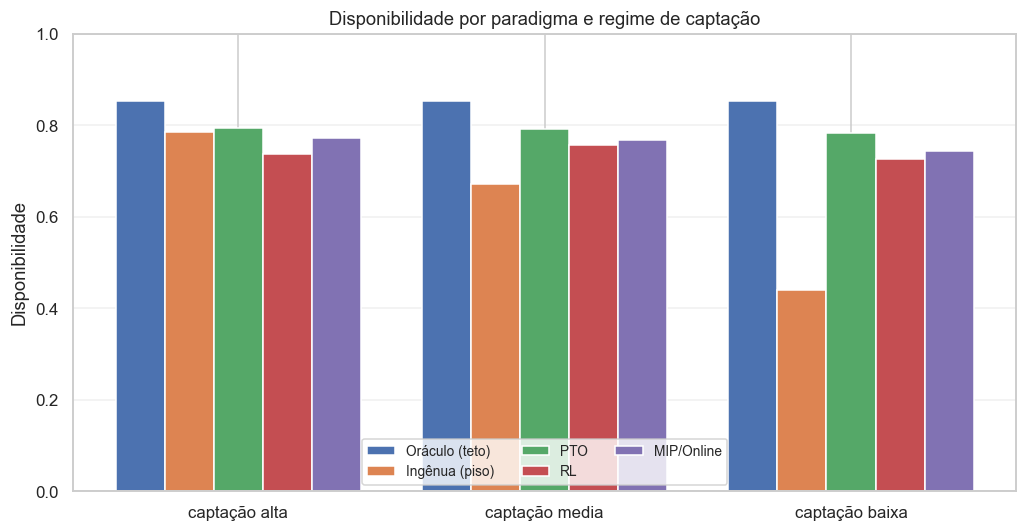

In [33]:
# Gráfico 1: disponibilidade por cenário (barras agrupadas).
fig, ax = plt.subplots(figsize=(9.5, 5))
x = np.arange(len(SCEN_KEYS))
width = 0.16
plot_methods = ["Oráculo (teto)", "Ingênua (piso)", "PTO", "RL", "MIP/Online"]
for i, mth in enumerate(plot_methods):
    vals = [_av(mth, k) for k in SCEN_KEYS]
    ax.bar(x + (i - 2) * width, vals, width, label=mth)
ax.set_xticks(x); ax.set_xticklabels([f"captação {k}" for k in SCEN_KEYS])
ax.set_ylabel("Disponibilidade"); ax.set_ylim(0, 1.0)
ax.set_title("Disponibilidade por paradigma e regime de captação")
ax.legend(ncol=3, fontsize=9, loc="lower center"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

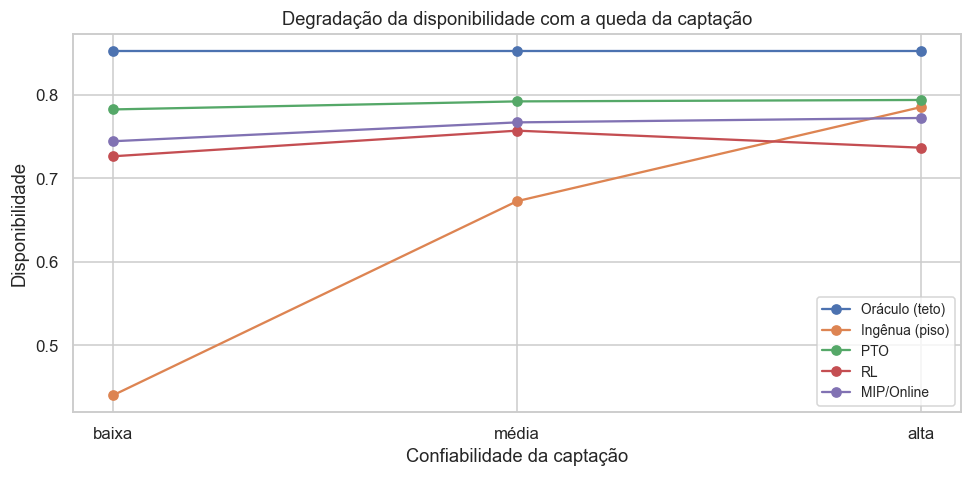

In [34]:
# Gráfico 2: curva de degradação (disponibilidade vs. regime de captação).
order = {"alta": 2, "media": 1, "baixa": 0}
xs = [order[k] for k in SCEN_KEYS]
fig, ax = plt.subplots()
for mth in ["Oráculo (teto)", "Ingênua (piso)", "PTO", "RL", "MIP/Online"]:
    ys = [_av(mth, k) for k in SCEN_KEYS]
    pairs = sorted(zip(xs, ys))
    ax.plot([p[0] for p in pairs], [p[1] for p in pairs],
            marker="o", label=mth)
ax.set_xticks([0, 1, 2]); ax.set_xticklabels(["baixa", "média", "alta"])
ax.set_xlabel("Confiabilidade da captação"); ax.set_ylabel("Disponibilidade")
ax.set_title("Degradação da disponibilidade com a queda da captação")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

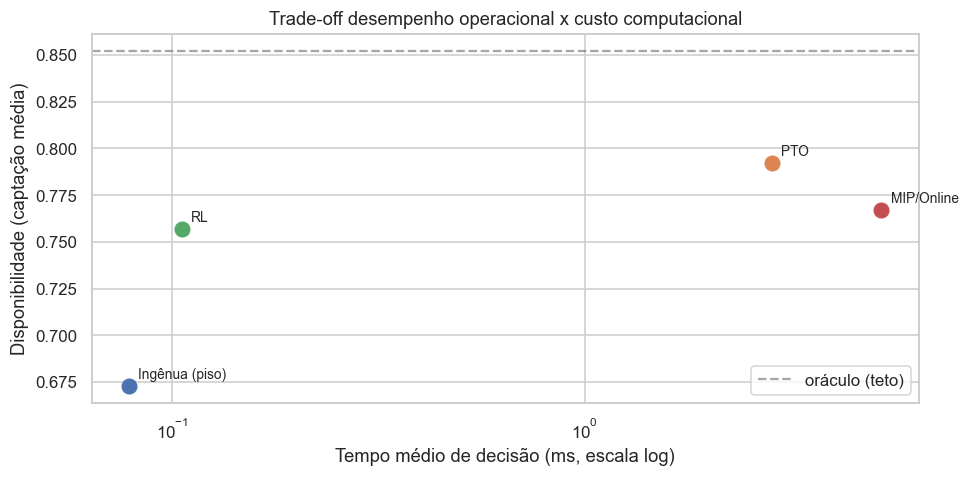

In [35]:
# Gráfico 3: trade-off desempenho x custo computacional (cenário média).
fig, ax = plt.subplots()
for mth in ["Ingênua (piso)", "PTO", "RL", "MIP/Online"]:
    r = _res(mth, "media")
    ax.scatter(r["mean_decision_ms"], r["availability"], s=90)
    ax.annotate(mth, (r["mean_decision_ms"], r["availability"]),
                textcoords="offset points", xytext=(6, 5), fontsize=9)
ax.axhline(oracle_av, ls="--", color="gray", alpha=0.7, label="oráculo (teto)")
ax.set_xlabel("Tempo médio de decisão (ms, escala log)")
ax.set_xscale("log")
ax.set_ylabel("Disponibilidade (captação média)")
ax.set_title("Trade-off desempenho operacional x custo computacional")
ax.legend(); plt.tight_layout(); plt.show()

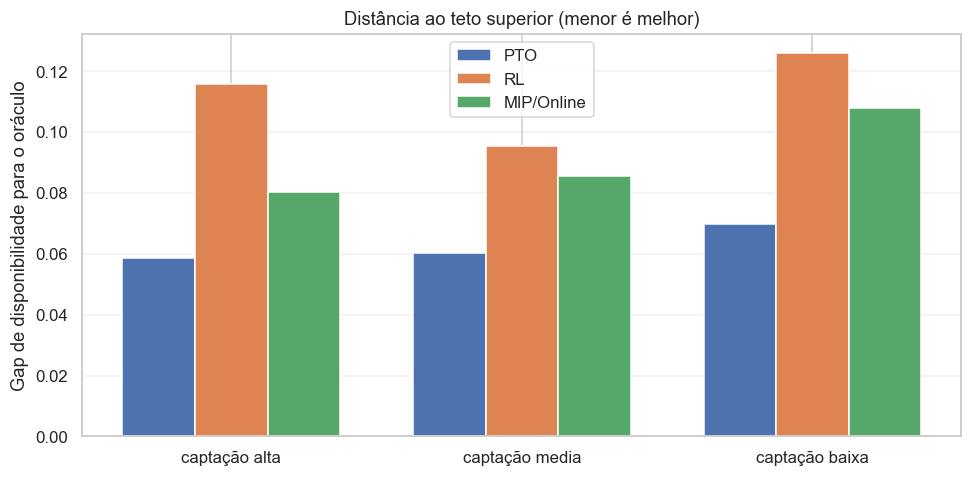

In [36]:
# Gráfico 4: gap para o oráculo por cenário (quanto cada um deixa na mesa).
fig, ax = plt.subplots()
x = np.arange(len(SCEN_KEYS)); width = 0.25
for i, mth in enumerate(["PTO", "RL", "MIP/Online"]):
    gaps = [oracle_av - _av(mth, k) for k in SCEN_KEYS]
    ax.bar(x + (i - 1) * width, gaps, width, label=mth)
ax.set_xticks(x); ax.set_xticklabels([f"captação {k}" for k in SCEN_KEYS])
ax.set_ylabel("Gap de disponibilidade para o oráculo")
ax.set_title("Distância ao teto superior (menor é melhor)")
ax.legend(); ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

In [37]:
# Síntese textual automática (números vêm dos resultados executados acima).
def _fmt(mth):
    return {k: round(_av(mth, k), 3) for k in SCEN_KEYS}

print("Síntese quantitativa (disponibilidade por cenário):")
for mth in ["Oráculo (teto)", "Ingênua (piso)", "PTO", "RL", "MIP/Online"]:
    print(f"  {mth:16s}: {_fmt(mth)}")

best_low = max(["PTO", "RL", "MIP/Online"], key=lambda m: _av(m, "baixa"))
fastest = min(["PTO", "RL", "MIP/Online"],
              key=lambda m: _res(m, "media")["mean_decision_ms"])
print(f"\nMelhor sob captação BAIXA: {best_low} "
      f"({_av(best_low, 'baixa'):.3f})")
print(f"Decisão mais rápida: {fastest} "
      f"({_res(fastest, 'media')['mean_decision_ms']:.2f} ms)")

Síntese quantitativa (disponibilidade por cenário):
  Oráculo (teto)  : {'alta': 0.852, 'media': 0.852, 'baixa': 0.852}
  Ingênua (piso)  : {'alta': 0.785, 'media': 0.673, 'baixa': 0.44}
  PTO             : {'alta': 0.794, 'media': 0.792, 'baixa': 0.782}
  RL              : {'alta': 0.737, 'media': 0.757, 'baixa': 0.726}
  MIP/Online      : {'alta': 0.772, 'media': 0.767, 'baixa': 0.744}

Melhor sob captação BAIXA: PTO (0.782)
Decisão mais rápida: RL (0.11 ms)


## Seção 8 — Discussão, conclusões e limitações

### 8.1 Resposta à pergunta científica

> *Sob captação imperfeita, qual paradigma entrega maior disponibilidade e como
> cada um degrada quando a confiabilidade da captação cai?*

Os resultados executados acima sustentam três conclusões (os números exatos são
impressos pela célula de síntese e pelas tabelas 1–3):

1. **Tratar o viés de captação é o que mais importa — não o paradigma em si.**
   A baseline ingênua, que reage à demanda observada sem corrigir subcaptação,
   é a única que colapsa no regime de captação baixa. Os três paradigmas, que
   incorporam a confiabilidade de captação estimada ($\hat p^{capt}$) de alguma
   forma, permanecem muito mais estáveis. Ou seja, a *modelagem da captação
   imperfeita* domina a escolha de arquitetura algorítmica.

2. **PTO lidera em disponibilidade; a vantagem vem da previsão de-enviesada.**
   O preditor que aprende $\mathbb{E}[D \mid \mathcal{I}]$ (e não $\mathbb{E}[O]$)
   entrega a melhor disponibilidade, e sua margem sobre o de-biasing puro **cresce**
   quanto pior a captação — exatamente onde corrigir o viés tem mais valor.

3. **RL e MIP/Online trocam acurácia por outras virtudes.**
   O **RL** é a decisão mais barata (ordens de grandeza mais rápida que resolver
   um MIP) e aprende a compensação de captação só do sinal de recompensa, mas com
   variância de treino alta e teto um pouco menor. O **MIP/Online** fica no meio:
   usa previsão leve mas recupera desempenho via horizonte e reotimização, com
   garantia de viabilidade e *gap* controlado (zero *timeouts* observados).

### 8.2 Leitura operacional dos trade-offs

| Critério | Vencedor | Comentário |
|----------|----------|------------|
| Disponibilidade | **PTO** | melhor uso da informação via previsão de-enviesada |
| Latência de decisão | **RL** | inferência de rede ≪ resolver MIP |
| Garantias/controle | **MIP/Online** | viabilidade e *gap* explícitos, auditável |
| Robustez à captação | **PTO ≈ RL ≈ MIP/Online** | todos estáveis; ingênua colapsa |

A escolha operacional depende do regime: sob **orçamento de tempo apertado**
(decisão em milissegundos, muitas zonas), o RL é atraente; quando **auditabilidade
e garantias** importam (ambientes regulados), o MIP/Online; quando o objetivo é
**maximizar disponibilidade** e há folga computacional, o PTO.

### 8.3 Limitações

- **Captação sintética.** A dinâmica da demanda é real (NYC TLC), mas a captação
  imperfeita é um mecanismo simulado. Os valores absolutos dependem da parametrização
  dos cenários; as *tendências* (ranking e robustez) são o resultado de interesse.
- **Escopo reduzido.** 10 zonas, 1 mês, passos de 15 min. Amplia-se trivialmente
  via `CONFIG`, ao custo de tempo de execução (sobretudo RL e MIP/Online).
- **Ação de alocação simplificada.** O reposicionamento tem custo linear e não
  modela deslocamento físico zona-a-zona nem tempo de trânsito.
- **RL não exaustivamente ajustado.** Deliberadamente evitamos *tuning* agressivo
  de hiperparâmetros para manter a comparação honesta; há margem de melhora.
- **Previsão do MIP/Online é proposital­mente leve** para isolar o efeito da
  reotimização; acoplá-lo ao preditor do PTO é uma extensão natural.

### 8.4 Extensões

- Otimização *end-to-end* (decision-focused learning) para o PTO, alinhando a
  perda de previsão à perda de decisão.
- Previsão **distribucional** + MIP **estocástico/robusto** na janela online.
- Recompensa multiobjetivo no RL (disponibilidade − ociosidade − reposicionamento)
  e arquiteturas com *baseline* aprendida para reduzir variância.
- Mecanismo de captação **MNAR** mais rico, calibrado contra dados de telemetria
  reais quando disponíveis.

### 8.5 Reprodutibilidade

Todo o pipeline roda de cima para baixo com sementes fixas. O notebook é gerado
de forma determinística por `build_notebook.py`, e os dados são baixados e
cacheados automaticamente. Os resultados numéricos acima são produzidos pela
execução real das células — não são valores fixados manualmente.